# Data Quality Checks and Preprocessing Decisions

**CS316 Electricity Theft Detection, Member 1 (data pipeline)**

This notebook shows the checks run on the two raw datasets and the
preprocessing decision each check led to. The cleaning itself is done by
the project code in `src/data_sgcc.py` and `src/data_oedi.py`
(run with `python -m src.prepare_data`).

Scope: data quality only (structure, missing values, outliers, labels).
Visual exploration of usage patterns is in the EDA notebook (Member 2).

## 0. Setup

Upload the raw files to Google Drive with this layout, then run the cells:

```
MyDrive/cs316-data/raw/sgcc/data.csv
MyDrive/cs316-data/raw/oedi/df.csv
```

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# In Colab: connect Google Drive. Elsewhere: set DATA_DIR to the local folder.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/cs316-data/raw"
except ImportError:
    DATA_DIR = "../data/raw"

SGCC_FILE = f"{DATA_DIR}/sgcc/data.csv"
OEDI_FILE = f"{DATA_DIR}/oedi/df.csv"
pd.set_option("display.max_columns", 15)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Part A: SGCC dataset

## A1. First look

In [26]:
# Read the readings as float32 instead of float64 to halve memory.
header = pd.read_csv(SGCC_FILE, nrows=0).columns
dtypes = {c: np.float32 for c in header if c not in ("CONS_NO", "FLAG")}
sgcc = pd.read_csv(SGCC_FILE, dtype=dtypes)

print("shape (customers, columns):", sgcc.shape)
print("memory (MB):", round(sgcc.memory_usage(deep=True).sum() / 1e6, 1))
sgcc.head()

shape (customers, columns): (42372, 1036)
memory (MB): 179.0


,CONS_NO,FLAG,2014/1/1,2014/1/10,2014/1/11,2014/1/12,2014/1/13,...,2016/9/30,2016/9/4,2016/9/5,2016/9/6,2016/9/7,2016/9/8,2016/9/9
0,0387DD8A07E07FDA6271170F86AD9151,1,NaN,NaN,NaN,NaN,NaN,...,7.60,27.219999,18.049999,26.469999,18.750000,17.840000,14.920000
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1,NaN,NaN,NaN,NaN,NaN,...,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,4B75AC4F2D8434CFF62DB64D0BB43103,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,B32AC8CC6D5D805AC053557AB05F5343,1,NaN,NaN,NaN,NaN,NaN,...,18.59,26.799999,18.570000,14.590000,12.820000,19.370001,15.920000
4,EDFC78B07BA2908B3395C4EB2304665E,1,2.9,3.42,3.81,4.58,3.56,...,13.51,12.230000,14.680000,16.350000,18.139999,18.410000,17.309999


In [27]:
sgcc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42372 entries, 0 to 42371
Columns: 1036 entries, CONS_NO to 2016/9/9
dtypes: float32(1034), int64(1), object(1)
memory usage: 167.8+ MB


**Result:** one row per customer (`CONS_NO`), a label (`FLAG`: 1 = theft,
0 = normal) and one column per day of usage in kWh.

## A2. Are the day columns in date order?

In [28]:
day_cols = sgcc.columns.drop(["CONS_NO", "FLAG"])
print("first 8 day columns:", list(day_cols[:8]))

dates = pd.to_datetime(day_cols, format="%Y/%m/%d")
print("in date order:", dates.is_monotonic_increasing)
print("range:", dates.min().date(), "to", dates.max().date())

all_days = pd.date_range(dates.min(), dates.max(), freq="D")
print("days in range:", len(all_days), "| day columns in file:", len(day_cols))
print("missing day(s):", [d.date() for d in all_days.difference(dates)])

first 8 day columns: ['2014/1/1', '2014/1/10', '2014/1/11', '2014/1/12', '2014/1/13', '2014/1/14', '2014/1/15', '2014/1/16']
in date order: False
range: 2014-01-01 to 2016-10-31
days in range: 1035 | day columns in file: 1034
missing day(s): [datetime.date(2016, 9, 18)]


**Decision:** the columns are sorted as text (`2014/1/1`, `2014/1/10`, ...),
not by date. We sort them by real date and add the one missing day as an
empty column, so the time series has no hole. It is filled with the other
gaps.

## A3. Missing values

In [29]:
readings = sgcc[day_cols]
total_missing = readings.isnull().sum().sum()
print(f"missing readings: {total_missing:,} of {readings.size:,} ({total_missing / readings.size:.1%})")
print("customers with at least one missing day:", readings.isnull().any(axis=1).sum())
print("customers with NO readings at all:", readings.isnull().all(axis=1).sum())

missing readings: 11,233,528 of 43,812,648 (25.6%)
customers with at least one missing day: 42372
customers with NO readings at all: 5


In [30]:
# Share of missing days per customer.
missing_share = readings.isnull().mean(axis=1)
missing_share.describe()

,0
count,42372.000000
mean,0.256399
std,0.288258
min,0.000967
25%,0.012573
50%,0.106383
75%,0.620164
max,1.000000


In [31]:
# Is missing data more common among theft customers?
missing_share.groupby(sgcc["FLAG"]).describe()

,count,mean,std,min,25%,50%,75%,max
FLAG,,,,,,,,
0,38757.0,0.250962,0.287227,0.000967,0.012573,0.092843,0.579304,1.0
1,3615.0,0.314687,0.292858,0.000967,0.022244,0.213733,0.705996,1.0


**Decisions:**
- Customers with no readings at all are removed.
- Every customer has some gaps, so rows cannot be dropped. Gaps are filled.
- Before filling, each customer's share of missing days is saved as a
  column (`missing_share`), since it differs between theft and normal
  customers and may be useful as a feature.

## A4. Duplicates and invalid values

In [32]:
print("duplicate rows:", sgcc.duplicated().sum())
print("duplicate customer IDs:", sgcc["CONS_NO"].duplicated().sum())
print("negative readings:", (readings < 0).sum().sum())

duplicate rows: 0
duplicate customer IDs: 0
negative readings: 0


**Decision:** no duplicates and no negative readings, so no action needed.

## A5. Extreme values

In [33]:
# describe() on all real daily readings (missing days excluded).
all_values = pd.Series(readings.to_numpy().ravel()).dropna()
all_values.describe(percentiles=[0.25, 0.5, 0.75, 0.99, 0.999])

,0
count,3.257912e+07
mean,9.258861e+00
std,2.729536e+02
min,0.000000e+00
25%,7.300000e-01
50%,4.590000e+00
75%,9.740000e+00
99%,6.979000e+01
99.9%,3.718588e+02
max,8.000033e+05


**Result:** 75% of daily readings are small, but the maximum is hundreds of
thousands of kWh, which is not realistic for one day. These look like
recording errors.

We cap them with the IQR rule, separately for each customer, because a
large business and a small home have different normal levels:
`upper limit = Q3 + k x IQR`. Readings above the limit are replaced by the
limit (not deleted). Low values and zeros are never changed.

### Choosing the IQR settings

We compared the usual `k = 1.5` with `k = 3` (Tukey's "extreme outlier"
fence), and computing Q1/Q3 on all days vs on non-zero days only.

In [34]:
def iqr_caps(r, k, nonzero_only):
    """True where a reading is above the customer's IQR upper limit."""
    base = r.where(r > 0) if nonzero_only else r
    q1, q3 = base.quantile(0.25, axis=1), base.quantile(0.75, axis=1)
    iqr = q3 - q1
    upper = (q3 + k * iqr).where(iqr > 0, np.inf)  # IQR = 0: skip customer
    return r.gt(upper, axis=0), int((iqr == 0).sum())

r = readings[~readings.isnull().all(axis=1)]
real = r.notnull().sum().sum()
rows = []
for nonzero_only in (False, True):
    for k in (1.5, 3.0):
        capped, skipped = iqr_caps(r, k, nonzero_only)
        n = capped.sum().sum()
        rows.append({"k": k, "Q1/Q3 from": "non-zero days" if nonzero_only else "all days",
                     "readings capped": n, "% of real readings": round(100 * n / real, 2),
                     "customers skipped (IQR=0)": skipped})
pd.DataFrame(rows)

,k,Q1/Q3 from,readings capped,% of real readings,customers skipped (IQR=0)
0,1.5,all days,1310452,4.02,5051
1,3.0,all days,488550,1.50,5051
2,1.5,non-zero days,1157989,3.55,394
3,3.0,non-zero days,377692,1.16,394


**Decision:** `k = 3` on non-zero days.
- Daily electricity use is skewed (many low days, some naturally high
  days). With `k = 1.5`, about 4% of all readings were capped, mostly normal
  high-usage days, not errors. `k = 3` caps about 1.2%.
- For customers with many zero days, Q1 and Q3 on all days are close to 0,
  so their normal usage would be capped. Using non-zero days avoids this.
- Customers whose IQR is still 0 are skipped.

### Example: one customer before and after capping

customer C096AE4A4620C4B59792DAEE3AA5042E: median 3.5 kWh, max 800,003 kWh, limit 8.0 kWh


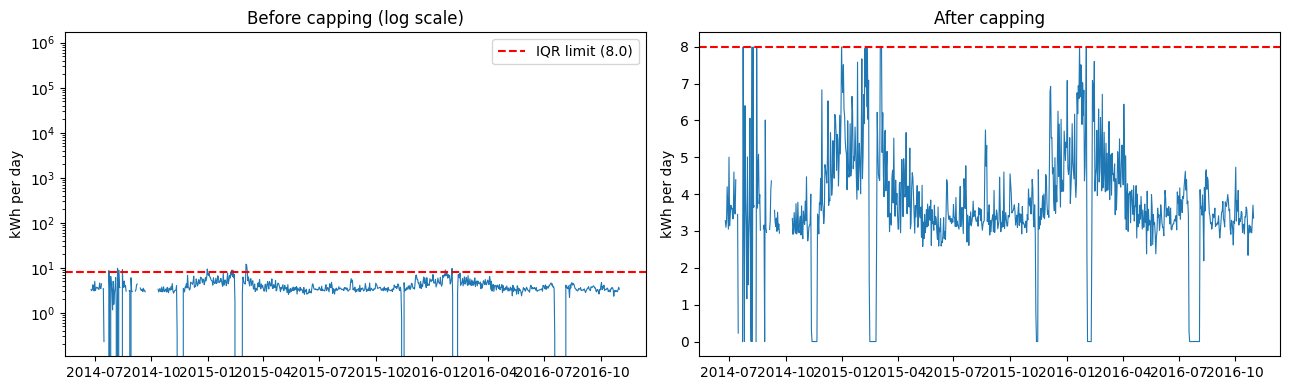

In [35]:
# The customer with the single largest reading in the dataset.
row = r.max(axis=1).idxmax()
series = r.loc[row].copy()
series.index = pd.to_datetime(series.index, format="%Y/%m/%d")
series = series.sort_index()

nonzero = series[series > 0]
q1, q3 = nonzero.quantile(0.25), nonzero.quantile(0.75)
limit = q3 + 3 * (q3 - q1)
capped = series.clip(upper=limit)
print(f"customer {sgcc.loc[row, 'CONS_NO']}: median {series.median():.1f} kWh, "
      f"max {series.max():,.0f} kWh, limit {limit:.1f} kWh")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(series, lw=0.8)
axes[0].axhline(limit, color="red", ls="--", label=f"IQR limit ({limit:.1f})")
axes[0].set_yscale("log")
axes[0].set_title("Before capping (log scale)")
axes[0].legend()
axes[1].plot(capped, lw=0.8)
axes[1].axhline(limit, color="red", ls="--")
axes[1].set_title("After capping")
for ax in axes:
    ax.set_ylabel("kWh per day")
plt.tight_layout()
plt.show()

## A6. How to fill the gaps

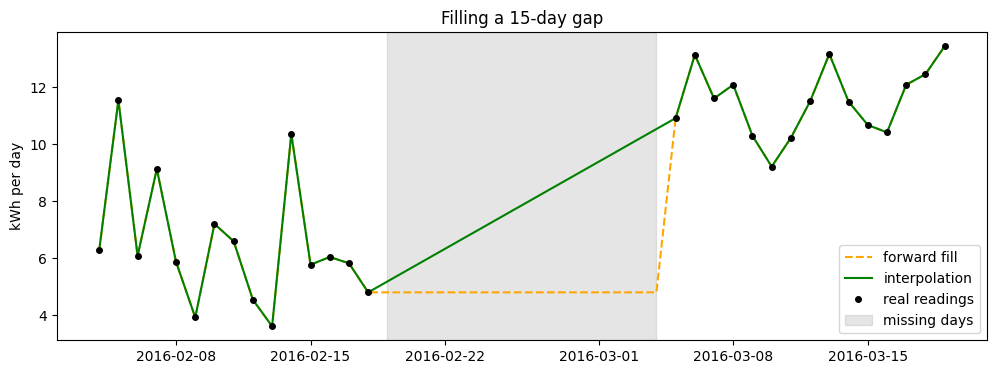

In [36]:
# Find a customer with a gap of 5 to 15 days in the middle of their series.
ordered = r.copy()
ordered.columns = pd.to_datetime(ordered.columns, format="%Y/%m/%d")
ordered = ordered.sort_index(axis=1)

def middle_gap(s, low=5, high=15):
    """Return (start, end) positions of a middle gap of the given length, or None."""
    is_na = s.isnull().to_numpy()
    i = 0
    while i < len(is_na):
        if is_na[i]:
            j = i
            while j < len(is_na) and is_na[j]:
                j += 1
            if 0 < i and j < len(is_na) and low <= j - i <= high:
                return i, j
            i = j
        else:
            i += 1
    return None

for idx in ordered.index:
    gap = middle_gap(ordered.loc[idx])
    if gap:
        break
s = ordered.loc[idx]
start, end = gap
window = s.iloc[max(start - 15, 0): end + 15]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(window.ffill(), "--", color="orange", label="forward fill")
ax.plot(window.interpolate(limit_area="inside"), "-", color="green", label="interpolation")
ax.plot(window, "o", color="black", ms=4, label="real readings")
ax.axvspan(s.index[start], s.index[end - 1], color="grey", alpha=0.2, label="missing days")
ax.set_ylabel("kWh per day")
ax.set_title(f"Filling a {end - start}-day gap")
ax.legend()
plt.show()

**Decision:**
- **Middle gaps:** linear interpolation. Usage changes gradually, and
  forward fill creates a flat line followed by a sudden jump, which could
  look like a sudden change in usage (a theft clue).
- **Start of a series:** backward fill. **End of a series:** forward fill.
  Interpolation needs known values on both sides, so it cannot fill these.
- Outliers are capped **before** filling, so extreme values do not spread
  into filled days.
- Each customer is filled using only their own readings (no leakage).

## A7. Labels and split

In [37]:
print(sgcc["FLAG"].value_counts())
print(sgcc["FLAG"].value_counts(normalize=True).round(3))

FLAG
0    38757
1     3615
Name: count, dtype: int64
FLAG
0    0.915
1    0.085
Name: proportion, dtype: float64


**Decision:** only about 8.5% of customers are labelled as theft, so the
80/20 train/test split is **stratified** by `FLAG` (both sets keep 8.5%
theft), with `random_state = 42`. Each row is one customer, so no customer
appears in both sets.

# Part B: OEDI dataset

## B1. First look

In [38]:
oedi = pd.read_csv(OEDI_FILE)
print("shape:", oedi.shape)
oedi.head()

shape: (560655, 13)


,0,Electricity:Facility [kW](Hourly),Fans:Electricity [kW](Hourly),Cooling:Electricity [kW](Hourly),Heating:Electricity [kW](Hourly),InteriorLights:Electricity [kW](Hourly),InteriorEquipment:Electricity [kW](Hourly),Gas:Facility [kW](Hourly),Heating:Gas [kW](Hourly),InteriorEquipment:Gas [kW](Hourly),Water Heater:WaterSystems:Gas [kW](Hourly),Class,theft
0,0,22.035977,3.586221,0.0,0.0,4.589925,8.1892,136.585903,123.999076,3.33988,9.246947,FullServiceRestaurant,Normal
1,1,14.649757,0.000000,0.0,0.0,1.529975,7.4902,3.359880,0.000000,3.33988,0.020000,FullServiceRestaurant,Normal
2,2,14.669567,0.000000,0.0,0.0,1.529975,7.4902,3.359880,0.000000,3.33988,0.020000,FullServiceRestaurant,Normal
3,3,14.677808,0.000000,0.0,0.0,1.529975,7.4902,3.931932,0.000000,3.33988,0.592052,FullServiceRestaurant,Normal
4,4,14.824794,0.000000,0.0,0.0,1.529975,7.4902,3.359880,0.000000,3.33988,0.020000,FullServiceRestaurant,Normal


In [39]:
oedi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 560655 entries, 0 to 560654
Data columns (total 13 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   0                                           560655 non-null  int64  
 1   Electricity:Facility [kW](Hourly)           560655 non-null  float64
 2   Fans:Electricity [kW](Hourly)               560655 non-null  float64
 3   Cooling:Electricity [kW](Hourly)            560655 non-null  float64
 4   Heating:Electricity [kW](Hourly)            560655 non-null  float64
 5   InteriorLights:Electricity [kW](Hourly)     560655 non-null  float64
 6   InteriorEquipment:Electricity [kW](Hourly)  560655 non-null  float64
 7   Gas:Facility [kW](Hourly)                   560655 non-null  float64
 8   Heating:Gas [kW](Hourly)                    560655 non-null  float64
 9   InteriorEquipment:Gas [kW](Hourly)          560655 non-null  float64
 

In [40]:
oedi.describe().T

,count,mean,std,min,25%,50%,75%,max
0,560655.0,280327.000000,161847.301923,0.0,140163.500000,280327.000000,420490.500000,560654.000000
Electricity:Facility [kW](Hourly),560655.0,161.775593,287.323654,0.0,15.843234,48.197262,155.448375,1726.432223
Fans:Electricity [kW](Hourly),560655.0,13.798083,24.078277,0.0,0.240958,3.557599,14.962478,240.015298
Cooling:Electricity [kW](Hourly),560655.0,43.770035,117.101272,0.0,0.000000,0.078813,16.838516,890.621907
Heating:Electricity [kW](Hourly),560655.0,0.836993,6.123290,0.0,0.000000,0.000000,0.000000,277.996520
InteriorLights:Electricity [kW](Hourly),560655.0,32.988238,65.177701,0.0,3.005316,9.233307,34.382155,448.566544
InteriorEquipment:Electricity [kW](Hourly),560655.0,42.631944,73.493664,0.0,4.950048,15.988889,41.401920,448.566544
Gas:Facility [kW](Hourly),560655.0,77.310902,178.680306,0.0,1.103003,11.905720,66.165380,4491.695087
Heating:Gas [kW](Hourly),560655.0,53.917106,157.721787,0.0,0.000000,0.083226,36.185902,4480.732902
InteriorEquipment:Gas [kW](Hourly),560655.0,8.163785,15.954861,0.0,0.000000,0.451244,7.575135,91.799800


In [41]:
print("column '0' equals the row number:", (oedi["0"] == np.arange(len(oedi))).all())
print("missing values per column:")
oedi.isnull().sum()

column '0' equals the row number: True
missing values per column:


,0
0,0
Electricity:Facility [kW](Hourly),0
Fans:Electricity [kW](Hourly),0
Cooling:Electricity [kW](Hourly),0
Heating:Electricity [kW](Hourly),0
InteriorLights:Electricity [kW](Hourly),0
InteriorEquipment:Electricity [kW](Hourly),0
Gas:Facility [kW](Hourly),0
Heating:Gas [kW](Hourly),0
InteriorEquipment:Gas [kW](Hourly),0


**Result and decision:** each row is one hour of usage for one building.
Column `0` is only the row number, so it is dropped. There are no missing
values, so no filling is needed.

## B2. Building types and labels

In [42]:
oedi["Class"].value_counts()

,count
Class,
FullServiceRestaurant,35040
Hospital,35040
LargeHotel,35040
LargeOffice,35040
MediumOffice,35040
MidriseApartment,35040
OutPatient,35040
PrimarySchool,35040
QuickServiceRestaurant,35040


In [43]:
oedi["theft"].value_counts()

,count
theft,
Normal,331824
Theft1,51083
Theft3,44349
Theft4,41460
Theft6,35413
Theft5,33553
Theft2,22973


**Decisions:**
- 15 rows have building type `"0"`; they are broken and removed.
- The label has 7 values. We create a 0/1 `theft` label (any theft type = 1)
  and keep the original as `theft_type` for error analysis.

## B3. Structure of the file

In [44]:
clean = oedi[oedi["Class"] != "0"].reset_index(drop=True)
recording = (clean["Class"] != clean["Class"].shift()).cumsum()
sizes = recording.value_counts()
print("number of recordings:", recording.nunique())
print("rows per recording:", sizes.unique())
print("recordings per building type:", clean.groupby("Class").size().div(8760).unique())

number of recordings: 64
rows per recording: [8760]
recordings per building type: [4.]


**Result:** the file is 64 one-year recordings (8,760 hours = 365 x 24):
16 building types x 4 recordings each. Comparing the 4 recordings of each
type showed they are similar but not copies (almost no identical hours),
and theft was added at different times in each.

## B4. Why a random split would leak

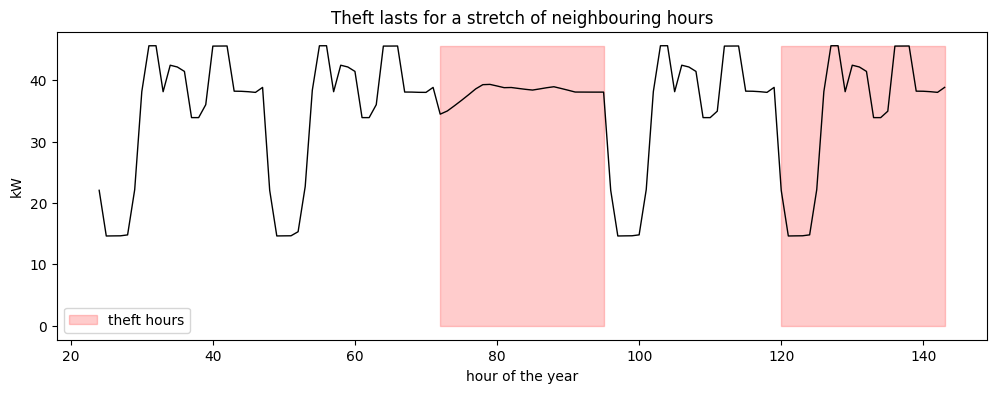

theft stretch length (hours):


,size
count,9835.000000
mean,23.265480
std,8.606969
min,1.000000
25%,24.000000
50%,24.000000
75%,24.000000
max,120.000000


In [45]:
elec = "Electricity:Facility [kW](Hourly)"
first = clean[recording == 1].reset_index(drop=True)
start = first.index[first["theft"] != "Normal"][0]
window = first.iloc[max(start - 48, 0): start + 72]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(window.index, window[elec], color="black", lw=1)
is_theft = window["theft"] != "Normal"
ax.fill_between(window.index, 0, window[elec].max(), where=is_theft,
                color="red", alpha=0.2, label="theft hours")
ax.set_xlabel("hour of the year")
ax.set_ylabel("kW")
ax.set_title("Theft lasts for a stretch of neighbouring hours")
ax.legend()
plt.show()

runs = (clean["theft"] != clean["theft"].shift()).cumsum()
lengths = clean.groupby(runs)["theft"].agg(["first", "size"])
print("theft stretch length (hours):")
lengths.loc[lengths["first"] != "Normal", "size"].describe()

**Decision:** theft lasts for stretches of neighbouring hours (typically
24). If rows were split at random, hours from the same theft stretch would
be in both training and test sets, and scores would be too optimistic.
Instead we split **by recording**: for each building type, 1 of its 4
recordings (chosen with seed 42) goes to the test set and 3 to training
(75/25). Every building type is seen in training, and test recordings are
never seen during training.

# Summary of preprocessing decisions

| Dataset | Issue found | Decision |
|---|---|---|
| SGCC | Day columns sorted as text; one day missing | Sort by date; add the missing day |
| SGCC | 5 customers with no readings | Remove |
| SGCC | 25.6% readings missing | Save `missing_share`; interpolate middle gaps, backward/forward fill edges |
| SGCC | Extreme readings (up to 800,003 kWh) | Cap per customer: IQR, k = 3, on non-zero days |
| SGCC | 8.5% theft | Stratified 80/20 split by customer |
| OEDI | Row-number column | Drop |
| OEDI | 15 broken rows | Remove |
| OEDI | 7 label values | Binary `theft` + `theft_type` |
| OEDI | Theft in stretches of neighbouring hours | Split by recording (1 of 4 per type to test) |
| Both | Memory | Readings stored as float32 |